# YOLO26: detect e-scooters in urban images
**Lab 8 · AI for Urban Sustainability · University of Pennsylvania**

This notebook fine-tunes a pretrained YOLO26 nano detector to find **stand-riding electric kick scooters** in urban photographs, then evaluates the selected model on images that were not used for training or validation.

**Class definition:** an `e-scooter` has small wheels, a standing deck, a handlebar, and no seat. Bicycles, motorcycles, seated mopeds, strollers, and wheelchairs are not labeled.

**Data and permission**

| Source | Images | Permission |
|---|---:|---|
| Kaggle: [Improper Scooter Parking Detection](https://www.kaggle.com/datasets/prodigyanalysis/improper-scooter-parking-detection), ProdigyAnalysis | 70 | MIT |
| Self-captured photographs, Philadelphia, 2026-10-24 | 30 | Author-owned |

The dataset contains 100 images and 171 annotated instances. Per-image provenance is stored in `sources.csv`.

**Before starting:** choose **Runtime → Change runtime type → T4 GPU**, then run cells from top to bottom.


## How this model works
YOLO predicts object classes and bounding boxes with a single detector network. We use the pretrained **YOLO26 nano** checkpoint to keep the experiment small enough for Colab. LabelMe rectangles are converted to YOLO detection labels; rectangles are not treated as segmentation masks.


## 1. Install packages


In [1]:
%pip install -q "torchmetrics==1.9.0" "pycocotools==2.0.11" "Pillow>=10" "matplotlib>=3.8" "ultralytics==8.4.170"


In [2]:
from pathlib import Path
from datetime import datetime
from collections import Counter
import csv, hashlib, json, random, shutil, subprocess, sys, zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cpu':
    print('Select a T4 GPU before training.')
WORK = Path('/content/urban-vision-lessons')
WORK.mkdir(parents=True, exist_ok=True)


PyTorch: 2.11.0+cu130 | Device: cuda


## 2. Load the annotated data
The archive contains the 100 images, matching LabelMe JSON files, the fixed grouped split, and `sources.csv`.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

ARCHIVE = Path('/content/drive/MyDrive/escooter_lab8_data.zip')
assert ARCHIVE.is_file(), f'Archive not found: {ARCHIVE}'
RAW_ROOT = WORK/'escooter-input'
if RAW_ROOT.exists():
    shutil.rmtree(RAW_ROOT)
RAW_ROOT.mkdir()
with zipfile.ZipFile(ARCHIVE) as z:
    for item in z.infolist():
        if not (RAW_ROOT/item.filename).resolve().is_relative_to(RAW_ROOT.resolve()):
            raise ValueError('Unsafe archive path')
    z.extractall(RAW_ROOT)

PACKAGE = RAW_ROOT/'escooter_lab8_data'
RAW = PACKAGE/'labelme'
SPLIT_FILE = PACKAGE/'split_assignment.json'
TASK = 'detect'
EPOCHS = 20
IMAGE_SIZE = 640
BATCH_SIZE = 2
RUN = WORK/('yolo-detect-escooter-' + datetime.now().strftime('%Y%m%d-%H%M%S'))
RUN.mkdir()
(RUN/'environment-freeze.txt').write_text(
    subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True))

with (PACKAGE/'sources.csv').open() as f:
    source_rows = list(csv.DictReader(f))
print('Images by permission:', dict(Counter(r['license'] for r in source_rows)))
print('Results folder:', RUN)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Images by permission: {'MIT': 70, 'own': 30}
Results folder: /content/urban-vision-lessons/yolo-detect-escooter-20261025-155211


## 3. Read and check the annotations
Checks image dimensions, labels, rectangle geometry, and exact duplicates before training.


In [4]:
def load_labelme(root):
    root = Path(root)
    records, warnings, seen = [], [], {}
    for path in sorted(root.glob('*.json')):
        data = json.loads(path.read_text())
        name = Path(data['imagePath'].replace('\\', '/')).name
        image_path = path.parent/name
        if not image_path.is_file():
            raise ValueError(f'{path.name}: matching image not found.')
        with Image.open(image_path) as im:
            if im.getexif().get(274, 1) != 1:
                raise ValueError(f'{name}: normalize image orientation before annotating.')
            rgb = im.convert('RGB'); width, height = rgb.size
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
        if (width, height) != (data.get('imageWidth'), data.get('imageHeight')):
            raise ValueError(f'{name}: image and annotation dimensions disagree.')
        if digest in seen:
            warnings.append(f'{name}: exact duplicate of {seen[digest]}; ignored.')
            continue
        seen[digest] = name
        objects = []
        for shape in data['shapes']:
            if shape.get('shape_type') != 'rectangle':
                raise ValueError(f'{name}: detection requires LabelMe rectangles.')
            label = shape['label'].strip()
            if label != 'e-scooter':
                raise ValueError(f'{name}: unexpected label {label!r}.')
            points = np.asarray(shape['points'], dtype=float)
            if points.shape != (2, 2) or not np.isfinite(points).all():
                raise ValueError(f'{name}: invalid rectangle coordinates.')
            clipped = np.clip(points, [0, 0], [width, height])
            if not np.array_equal(clipped, points):
                warnings.append(f'{name}: rectangle clipped to image boundary.')
            x1, y1 = clipped.min(axis=0); x2, y2 = clipped.max(axis=0)
            if x2 <= x1 or y2 <= y1:
                raise ValueError(f'{name}: zero-area rectangle.')
            objects.append({'label': label, 'box': [float(x1), float(y1), float(x2), float(y2)]})
        records.append({'id': path.name, 'image': str(image_path.resolve()),
                        'width': width, 'height': height, 'objects': objects,
                        'sha256': digest})
    if len(records) != 100:
        raise ValueError(f'Expected 100 annotated images, found {len(records)}.')
    print(f'{len(records)} images; {sum(len(r["objects"]) for r in records)} objects; class: e-scooter')
    for warning in warnings:
        print('Annotation note:', warning)
    return records, ['e-scooter'], warnings


def make_splits(records, split_file):
    assignment = json.loads(Path(split_file).read_text())
    ids = {r['id'] for r in records}
    if set(assignment) != ids or set(assignment.values()) != {'train', 'val', 'test'}:
        raise ValueError('Split file must assign every image to train, val, or test.')
    splits = {s: [r for r in records if assignment[r['id']] == s]
              for s in ['train', 'val', 'test']}
    for split, rows in splits.items():
        print(split, len(rows), 'images;', sum(len(r['objects']) for r in rows), 'objects')
    return splits, assignment


def draw_ground_truth(record):
    image = Image.open(record['image']).convert('RGB')
    draw = ImageDraw.Draw(image)
    for obj in record['objects']:
        draw.rectangle(obj['box'], outline='lime', width=3)
        draw.text(tuple(obj['box'][:2]), obj['label'], fill='red')
    return image


def export_yolo(splits, names, output):
    output = Path(output)
    if output.exists():
        raise ValueError('Choose a new YOLO export folder.')
    for split, rows in splits.items():
        (output/'images'/split).mkdir(parents=True)
        (output/'labels'/split).mkdir(parents=True)
        for index, record in enumerate(rows):
            with Image.open(record['image']) as image:
                image.convert('RGB').save(output/'images'/split/f'{index:06}.png')
            lines = []
            for obj in record['objects']:
                x1, y1, x2, y2 = obj['box']; w, h = record['width'], record['height']
                values = [(x1+x2)/2/w, (y1+y2)/2/h, (x2-x1)/w, (y2-y1)/h]
                lines.append('0 ' + ' '.join(f'{value:.8f}' for value in values))
            (output/'labels'/split/f'{index:06}.txt').write_text('\n'.join(lines))
    data = {'path': str(output.resolve()), 'train': 'images/train',
            'val': 'images/val', 'test': 'images/test', 'names': names}
    (output/'data.yaml').write_text(json.dumps(data, indent=2))
    return output/'data.yaml'


100 images; 171 objects; class: e-scooter


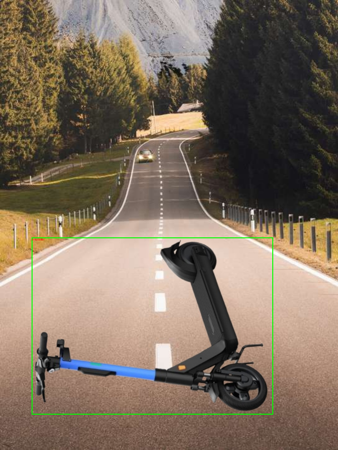

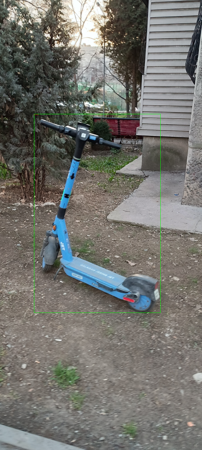

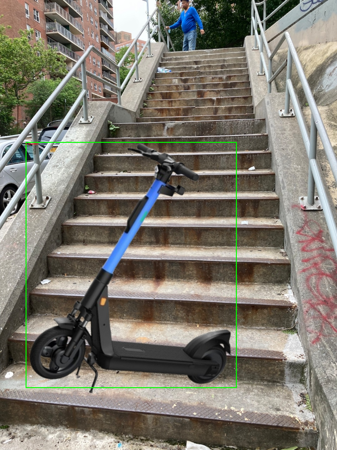

In [5]:
records, CLASS_NAMES, annotation_notes = load_labelme(RAW)
for record in records[:3]:
    preview = draw_ground_truth(record)
    preview.thumbnail((650, 450)); display(preview)


## 4. Keep training and evaluation separate
- **Training:** 70 images used to update weights.
- **Validation:** 15 images used to select `best.pt`.
- **Test:** 15 untouched images used once for final reporting.

The split is fixed in `split_assignment.json`.

In [6]:
splits, assignment = make_splits(records, SPLIT_FILE)
(RUN/'split_assignment.json').write_text(json.dumps(assignment, indent=2, sort_keys=True))
manifest = [{k: v for k, v in record.items() if k != 'image'} for record in records]
(RUN/'dataset_manifest.json').write_text(json.dumps(manifest, indent=2))
(RUN/'annotation_notes.json').write_text(json.dumps(annotation_notes, indent=2))
(RUN/'lesson_config.json').write_text(json.dumps({
    'task': TASK, 'classes': CLASS_NAMES, 'epochs': EPOCHS,
    'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
    'seed': SEED, 'split_method': 'grouped explicit 70/15/15'
}, indent=2))


train 70 images; 113 objects
val 15 images; 27 objects
test 15 images; 31 objects


175

## 5. Shared prediction and evaluation helpers
TorchMetrics computes COCO-style AP on original image coordinates. **AP50** accepts IoU ≥ 0.50; **AP50–95** averages IoU thresholds from 0.50 to 0.95.


In [7]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision


def target_for_record(record):
    return {
        'boxes': torch.tensor([o['box'] for o in record['objects']], dtype=torch.float32).reshape(-1, 4),
        'labels': torch.zeros(len(record['objects']), dtype=torch.int64)
    }


def predict_yolo(model, record):
    result = model.predict(record['image'], device=0 if DEVICE.type == 'cuda' else 'cpu',
                           imgsz=IMAGE_SIZE, conf=0.001, max_det=100, verbose=False)[0]
    return {'boxes': result.boxes.xyxy.cpu(),
            'labels': result.boxes.cls.cpu().long(),
            'scores': result.boxes.conf.cpu()}


def evaluate_predictions(rows, predict_one):
    metric = MeanAveragePrecision(iou_type='bbox', class_metrics=True)
    for record in rows:
        metric.update([predict_one(record)], [target_for_record(record)])
    result = metric.compute()
    return {key: float(result[key]) for key in ['map', 'map_50', 'map_75', 'mar_100']}


def draw_prediction(record, prediction, threshold=0.5):
    image = Image.open(record['image']).convert('RGB')
    draw = ImageDraw.Draw(image)
    keep = prediction['scores'] >= threshold
    for box, score in zip(prediction['boxes'][keep], prediction['scores'][keep]):
        draw.rectangle(box.tolist(), outline='red', width=3)
        draw.text(tuple(box[:2].tolist()), f'e-scooter: {float(score):.2f}', fill='red')
    return image, int(keep.sum())


## 6. Export the labels for YOLO
YOLO detection labels store class ID, box center, width, and height normalized by image size. Class IDs begin at 0; there is no explicit background class.


In [8]:
DATA_YAML = export_yolo(splits, CLASS_NAMES, RUN/'yolo-data')
example_label = sorted((RUN/'yolo-data/labels/train').glob('*.txt'))[0]
print('Example label file:', example_label.name)
print(example_label.read_text())


Example label file: 000000.txt
0 0.45104693 0.72435087 0.71327862 0.39346295


## 7. Fine-tune a pretrained YOLO model
Settings: YOLO26n, 640-pixel input, batch size 2, seed 42, and no mosaic or color augmentation. Horizontal flipping remains enabled. The best checkpoint is selected from validation performance.


New https://pypi.org/project/ultralytics/8.4.189 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/urban-vision-lessons/yolo-detect-escooter-20261025-155211/yolo-data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det

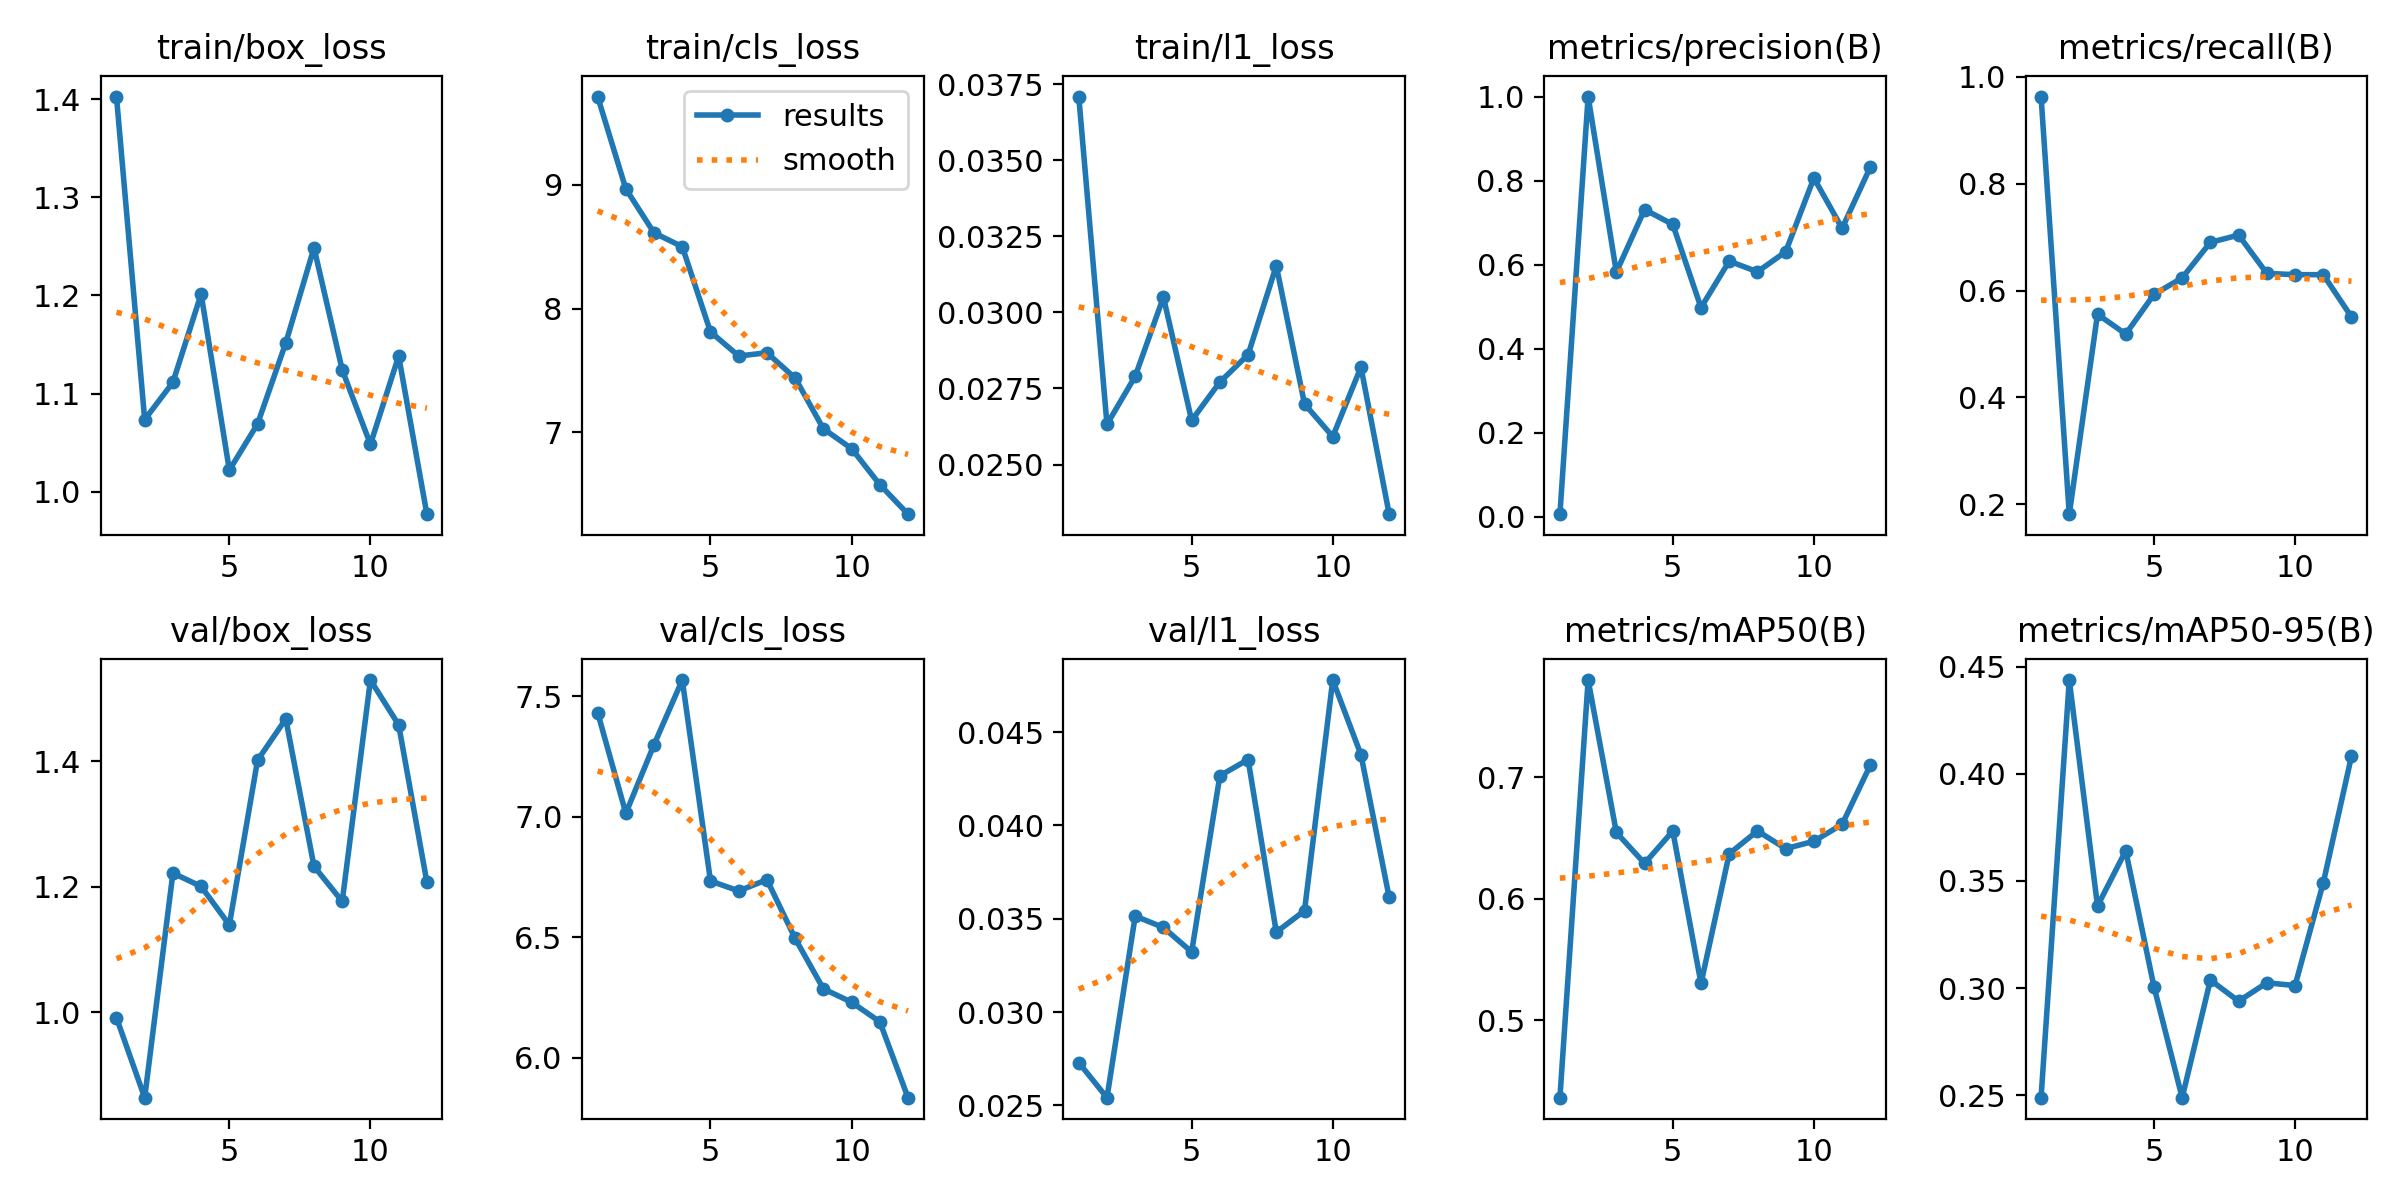

In [9]:
from ultralytics import YOLO

train_model = YOLO('yolo26n.pt')
train_model.train(
    data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
    device=0 if DEVICE.type == 'cuda' else 'cpu', workers=0, seed=SEED,
    project=str(RUN), name='training', exist_ok=False, patience=10,
    mosaic=0.0, mixup=0.0, copy_paste=0.0,
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5, plots=True)
TRAIN_RUN = Path(train_model.trainer.save_dir)
BEST = TRAIN_RUN/'weights/best.pt'
assert BEST.is_file(), 'No checkpoint found; inspect the training output.'
if (TRAIN_RUN/'results.png').exists():
    display(Image.open(TRAIN_RUN/'results.png'))


## 8. Reload the best model and evaluate validation data
YOLO chooses `best.pt` using its built-in validation fitness. Reload that checkpoint and use the course evaluator for the reported metrics.


In [10]:
best_model = YOLO(str(BEST))
predict_one = lambda record: predict_yolo(best_model, record)
validation_metrics = evaluate_predictions(splits['val'], predict_one)
print(json.dumps(validation_metrics, indent=2))
(RUN/'validation_metrics.json').write_text(json.dumps(validation_metrics, indent=2))


{
  "map": 0.45488205552101135,
  "map_50": 0.7274344563484192,
  "map_75": 0.5205352902412415,
  "mar_100": 0.7037037014961243
}


129

## 9. Final test — after choosing the model
The test split is evaluated once after the validation-selected checkpoint is fixed.


In [11]:
standard_test = best_model.val(
    data=str(DATA_YAML), split='test', imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
    device=0 if DEVICE.type == 'cuda' else 'cpu', workers=0,
    plots=False, project=str(RUN), name='test-evaluation',
    exist_ok=True, verbose=False)
course_test = evaluate_predictions(splits['test'], predict_one)
test_metrics = {
    'precision': float(standard_test.box.mp),
    'recall': float(standard_test.box.mr),
    'map': course_test['map'],
    'map_50': course_test['map_50'],
    'map_75': course_test['map_75'],
    'mar_100': course_test['mar_100']}
print(json.dumps(test_metrics, indent=2))
(RUN/'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))


Ultralytics 8.4.170 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 120 layers, 2,375,031 parameters, 0 gradients, 5.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3768.0±821.2 MB/s, size: 1400.5 KB)
val: Scanning /content/urban-vision-lessons/yolo-detect-escooter-20261025-155211/yolo-data/labels/test... 15 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 15/15 658.9it/s 0.0s
val: New cache created: /content/urban-vision-lessons/yolo-detect-escooter-20261025-155211/yolo-data/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 8.2it/s 1.0s
                   all         15         31      0.724      0.484      0.573      0.305
Speed: 0.4ms preprocess, 19.7ms inference, 0.0ms loss, 1.6ms postprocess per image
{
  "precision": 0.7236683967604897,
  "recall": 0.4838709677419355,
  "map": 0.30990874767303467,
  "map_50": 0.6298277378082275,
  "map_75": 0.3194

196

## 10. Look at successes and failures
Left: annotation. Right: prediction.

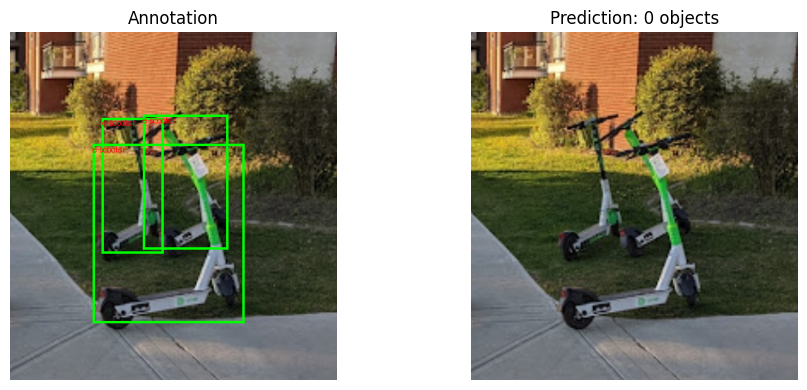

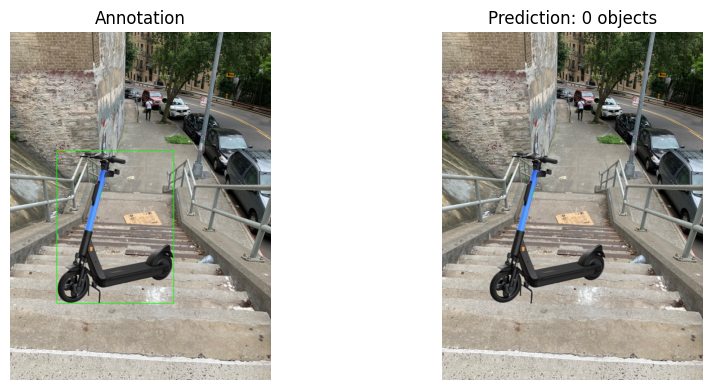

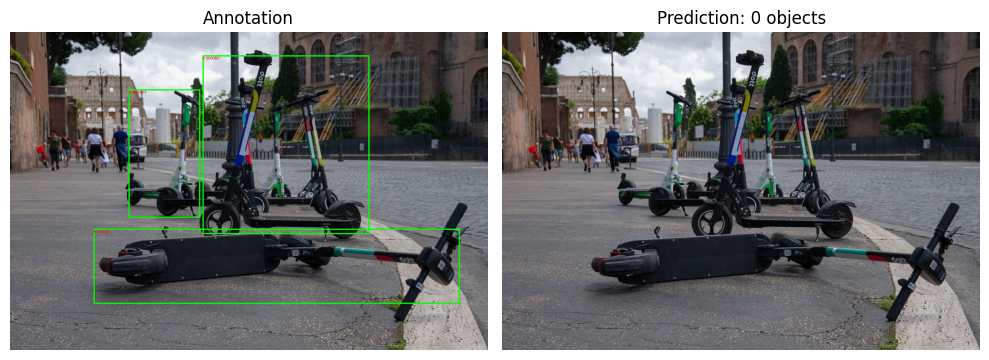

In [12]:
DISPLAY_THRESHOLD = 0.5
for record in splits['test'][:3]:
    prediction = predict_one(record)
    predicted_image, count = draw_prediction(record, prediction, DISPLAY_THRESHOLD)
    figure, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(draw_ground_truth(record)); axes[0].set_title('Annotation')
    axes[1].imshow(predicted_image); axes[1].set_title(f'Prediction: {count} objects')
    for axis in axes: axis.axis('off')
    plt.tight_layout(); plt.show()


## Results and limitations

### Evaluation protocol
The validation set selected `best.pt`; the test set was then evaluated once. Test precision and recall come directly from the standard Ultralytics detector summary. AP values use the course example's TorchMetrics evaluator: AP50 counts a prediction as a match at IoU ≥ 0.50, AP75 uses IoU ≥ 0.75, and AP50–95 averages thresholds from 0.50 through 0.95. The numerical validation and test results are printed directly above.

### Interpretation
The model detects many clear, medium-to-large parked e-scooters, while performance decreases for small, partly occluded, distant, or unusually framed instances. The three test panels compare annotations with predictions and illustrate successful detection as well as missed or poorly localized objects. Because the final checkpoint was chosen only from validation performance, the test results remain an estimate of generalization rather than a tuning target.

### Limitations
This is a small proof-of-concept dataset: 100 images from one Kaggle collection and one self-capture day. Every image contains at least one scooter, so the data provide limited evidence about false alarms in background-only streets or around bicycles and motorcycles. Results may also vary because the validation and test splits contain only 15 images each.


## 11. Save the submission
The submission archive contains the best checkpoint, validation and test metrics, exact split, annotation record, settings, package versions, source table, and training results.


In [13]:
bundle = RUN/'submission'; bundle.mkdir(exist_ok=True)
shutil.copy2(BEST, bundle/'best.pt')
for name in ['test_metrics.json', 'validation_metrics.json', 'split_assignment.json',
             'dataset_manifest.json', 'annotation_notes.json', 'lesson_config.json',
             'environment-freeze.txt']:
    shutil.copy2(RUN/name, bundle/name)
shutil.copy2(PACKAGE/'sources.csv', bundle/'sources.csv')
if (TRAIN_RUN/'results.csv').exists():
    shutil.copy2(TRAIN_RUN/'results.csv', bundle/'training_results.csv')
archive_path = shutil.make_archive(str(RUN/'lab8-escooter-submission'), 'zip', bundle)
destination = Path('/content/drive/MyDrive/escooter-lab8-results')
destination.mkdir(exist_ok=True)
saved = destination/'lab8-escooter-submission.zip'
shutil.copy2(archive_path, saved)
print('Saved:', saved)


Saved: /content/drive/MyDrive/escooter-lab8-results/lab8-escooter-submission.zip
